
# Population and Migration Analysis in Newfoundland and Labrador (2000–2025)

## Мета дослідження

Проаналізувати демографічні зміни в провінції Ньюфаундленд і Лабрадор протягом 2000–2025 років та визначити основні фактори, які впливали на чисельність населення.

**Основні питання дослідження:**
- Як змінювалася чисельність населення протягом 25 років?
- Як народжуваність і смертність впливали на природний приріст населення?
- Яку роль відігравали міжнародна та міжпровінційна міграція?
- Які демографічні тенденції змінилися після 2021 року?

**Джерело даних:** Statistics Canada.

**Інструменти:** Python, Pandas, Matplotlib, Jupyter Notebook.

## 1. Завантаження та первинний огляд даних
На цьому етапі імпортуємо необхідні бібліотеки, перевіряємо доступність файлів і завантажуємо дані Statistics Canada для подальшого аналізу.
Дані містять інформацію про чисельність населення, його вікову структуру та компоненти демографічних змін.

In [1]:
import pandas as pd


In [2]:
# Імпортуємо Path для роботи зі шляхами до файлів
from pathlib import Path
# Вказуємо шлях до папки з оригінальними даними
data_path = Path("../data/raw")
# Перевіряємо, чи існує папка з даними
print(data_path.exists())

True


In [3]:
# Знаходимо всі CSV-файли в папці з даними та її підпапках
files = list(data_path.rglob("*.csv"))
for file in files:
    print(file)

../data/raw/17100005-eng/17100005_MetaData.csv
../data/raw/17100005-eng/17100005.csv
../data/raw/17100015-eng/17100015.csv
../data/raw/17100015-eng/17100015_MetaData.csv
../data/raw/17100008-eng/17100008_MetaData.csv
../data/raw/17100008-eng/17100008.csv
../data/raw/17100022-eng/17100022_MetaData.csv
../data/raw/17100022-eng/17100022.csv


In [4]:
# Вказуємо шлях до файлу з даними про населення
file_path = data_path / "17100005-eng" / "17100005.csv"
df = pd.read_csv(file_path, nrows=5)
df

,REF_DATE,GEO,DGUID,Gender,Age group,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,1971,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,21962032,NaN,NaN,NaN,0
1,1971,Canada,2021A000011124,Total - gender,0 to 4 years,Persons,249,units,0,v466884,1.1.7,1836149,NaN,NaN,NaN,0
2,1971,Canada,2021A000011124,Total - gender,0 years,Persons,249,units,0,v466719,1.1.2,360077,NaN,NaN,NaN,0
3,1971,Canada,2021A000011124,Total - gender,1 year,Persons,249,units,0,v466752,1.1.3,364890,NaN,NaN,NaN,0
4,1971,Canada,2021A000011124,Total - gender,2 years,Persons,249,units,0,v466785,1.1.4,359388,NaN,NaN,NaN,0


In [5]:
# Переглядаємо основні поля, необхідні для демографічного аналізу
df[["REF_DATE", "GEO", "Gender", "Age group", "VALUE", "STATUS"]]

,REF_DATE,GEO,Gender,Age group,VALUE,STATUS
0,1971,Canada,Total - gender,All ages,21962032,NaN
1,1971,Canada,Total - gender,0 to 4 years,1836149,NaN
2,1971,Canada,Total - gender,0 years,360077,NaN
3,1971,Canada,Total - gender,1 year,364890,NaN
4,1971,Canada,Total - gender,2 years,359388,NaN


In [6]:
# Завантажуємо повний набір даних про населення
df = pd.read_csv(file_path, low_memory=False)
# Перевіряємо, які географічні регіони представлені в даних
df["GEO"].unique()

array(['Canada', 'Newfoundland and Labrador', 'Prince Edward Island',
       'Nova Scotia', 'New Brunswick', 'Quebec', 'Ontario', 'Manitoba',
       'Saskatchewan', 'Alberta', 'British Columbia', 'Yukon',
       'Northwest Territories including Nunavut', 'Northwest Territories',
       'Nunavut'], dtype=object)

## 2. Фільтрація та підготовка даних
Оскільки початковий набір даних охоплює всю Канаду та тривалий історичний період, для дослідження відбираємо лише дані провінції Ньюфаундленд і Лабрадор за 2000–2025 роки.
На цьому етапі також залишаємо необхідні для аналізу стовпці та перевіряємо наявність спеціальних позначок у даних.

In [7]:
# Відбираємо дані лише для провінції Newfoundland and Labrador
df_nl = df[df["GEO"] == "Newfoundland and Labrador"]
df_nl.head()

,REF_DATE,GEO,DGUID,Gender,Age group,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
378,1971,Newfoundland and Labrador,2021A000210,Total - gender,All ages,Persons,249,units,0,v466983,2.1.1,530854.0,NaN,NaN,NaN,0
379,1971,Newfoundland and Labrador,2021A000210,Total - gender,0 to 4 years,Persons,249,units,0,v467199,2.1.7,62136.0,NaN,NaN,NaN,0
380,1971,Newfoundland and Labrador,2021A000210,Total - gender,0 years,Persons,249,units,0,v467034,2.1.2,12095.0,NaN,NaN,NaN,0
381,1971,Newfoundland and Labrador,2021A000210,Total - gender,1 year,Persons,249,units,0,v467067,2.1.3,12254.0,NaN,NaN,NaN,0
382,1971,Newfoundland and Labrador,2021A000210,Total - gender,2 years,Persons,249,units,0,v467100,2.1.4,12218.0,NaN,NaN,NaN,0


In [8]:
# Перевіряємо, за які роки доступні дані для провінції
df_nl["REF_DATE"].unique()

array([1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981,
       1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992,
       1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003,
       2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014,
       2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025,
       2026])

In [9]:
# Відбираємо дані за 2000–2025 роки
df_nl_clean = df_nl.loc[
    df_nl["REF_DATE"].between(2000, 2025),
    ["REF_DATE", "GEO", "Gender", "Age group", "VALUE"]
].copy()

df_nl_clean.head()

,REF_DATE,GEO,Gender,Age group,VALUE
151239,2000,Newfoundland and Labrador,Total - gender,All ages,527966.0
151240,2000,Newfoundland and Labrador,Total - gender,0 to 4 years,26312.0
151241,2000,Newfoundland and Labrador,Total - gender,0 years,5115.0
151242,2000,Newfoundland and Labrador,Total - gender,1 year,4972.0
151243,2000,Newfoundland and Labrador,Total - gender,2 years,5191.0


In [10]:
df_nl_clean["Gender"].unique()

array(['Total - gender', 'Men+', 'Women+'], dtype=object)

In [11]:
df_nl_clean["Age group"].unique()

array(['All ages', '0 to 4 years', '0 years', '1 year', '2 years',
       '3 years', '4 years', '5 to 9 years', '5 years', '6 years',
       '7 years', '8 years', '9 years', '10 to 14 years', '10 years',
       '11 years', '12 years', '13 years', '14 years', '15 to 19 years',
       '15 years', '16 years', '17 years', '18 years', '19 years',
       '20 to 24 years', '20 years', '21 years', '22 years', '23 years',
       '24 years', '25 to 29 years', '25 years', '26 years', '27 years',
       '28 years', '29 years', '30 to 34 years', '30 years', '31 years',
       '32 years', '33 years', '34 years', '35 to 39 years', '35 years',
       '36 years', '37 years', '38 years', '39 years', '40 to 44 years',
       '40 years', '41 years', '42 years', '43 years', '44 years',
       '45 to 49 years', '45 years', '46 years', '47 years', '48 years',
       '49 years', '50 to 54 years', '50 years', '51 years', '52 years',
       '53 years', '54 years', '55 to 59 years', '55 years', '56 years',
     

In [12]:
population = df_nl_clean.query(
    "Gender == 'Total - gender' and `Age group` == 'All ages'"
).copy()

population[["REF_DATE", "VALUE"]].head()

,REF_DATE,VALUE
151239,2000,527966.0
157077,2001,522043.0
162915,2002,519411.0
168753,2003,518389.0
174591,2004,517375.0


### Висновок: первинна перевірка та очищення даних

Після завантаження даних Statistics Canada було відібрано записи для провінції Newfoundland and Labrador за 2000–2025 роки.

Для подальшого аналізу залишено основні показники: рік, провінція, стать, вікова група та чисельність населення (`VALUE`).

Підготовлені дані можна використовувати для дослідження демографічних змін.

## 3. Аналіз чисельності населення (2000–2025)

У цьому розділі досліджуємо, як змінювалася загальна чисельність населення провінції Ньюфаундленд і Лабрадор протягом 2000–2025 років.

Для аналізу використовуємо показник `VALUE` для всіх вікових груп (`All ages`) та всіх статей (`Total - gender`). Результати представимо у вигляді таблиці та лінійного графіка.

In [13]:
population[["REF_DATE", "VALUE"]]


,REF_DATE,VALUE
151239,2000,527966.0
157077,2001,522043.0
162915,2002,519411.0
168753,2003,518389.0
174591,2004,517375.0
180429,2005,514310.0
186267,2006,510593.0
192105,2007,509047.0
197943,2008,511569.0
203781,2009,516741.0


<Axes: title={'center': 'Population of Newfoundland and Labrador (2000–2025)'}, xlabel='Year', ylabel='Population'>

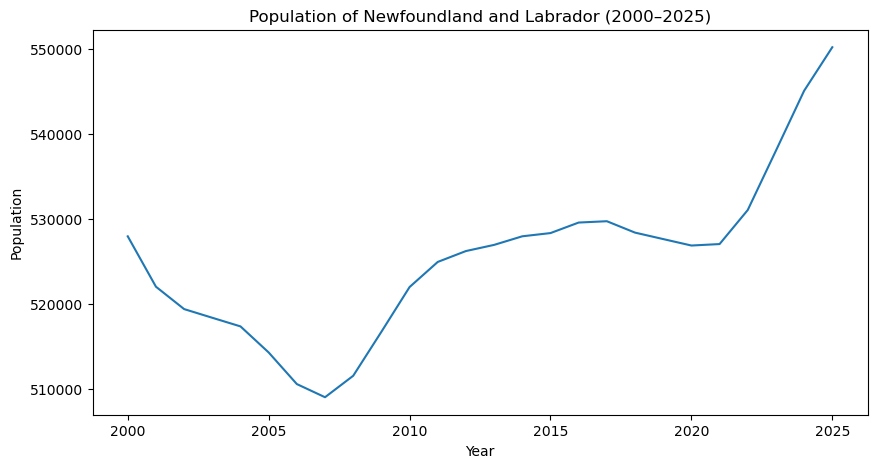

In [14]:
population.plot(
    x="REF_DATE",
    y="VALUE",
    kind="line",
    title="Population of Newfoundland and Labrador (2000–2025)",
    xlabel="Year",
    ylabel="Population",
    legend=False,
    figsize=(10, 5)
)

In [15]:
population["Change"] = population["VALUE"].diff()

population[["REF_DATE", "VALUE", "Change"]]

,REF_DATE,VALUE,Change
151239,2000,527966.0,NaN
157077,2001,522043.0,-5923.0
162915,2002,519411.0,-2632.0
168753,2003,518389.0,-1022.0
174591,2004,517375.0,-1014.0
180429,2005,514310.0,-3065.0
186267,2006,510593.0,-3717.0
192105,2007,509047.0,-1546.0
197943,2008,511569.0,2522.0
203781,2009,516741.0,5172.0


In [16]:
population.loc[population["Change"].idxmax()]

REF_DATE                          2024
GEO          Newfoundland and Labrador
Gender                  Total - gender
Age group                     All ages
VALUE                         545080.0
Change                          7039.0
Name: 291351, dtype: object

In [17]:
population["Growth_pct"] = population["VALUE"].pct_change() * 100

population[["REF_DATE", "VALUE", "Change", "Growth_pct"]]

,REF_DATE,VALUE,Change,Growth_pct
151239,2000,527966.0,NaN,NaN
157077,2001,522043.0,-5923.0,-1.121853
162915,2002,519411.0,-2632.0,-0.504173
168753,2003,518389.0,-1022.0,-0.196761
174591,2004,517375.0,-1014.0,-0.195606
180429,2005,514310.0,-3065.0,-0.592414
186267,2006,510593.0,-3717.0,-0.722716
192105,2007,509047.0,-1546.0,-0.302785
197943,2008,511569.0,2522.0,0.495436
203781,2009,516741.0,5172.0,1.011007


In [18]:
population.loc[population["Growth_pct"].idxmax()]

REF_DATE                           2023
GEO           Newfoundland and Labrador
Gender                   Total - gender
Age group                      All ages
VALUE                          538041.0
Change                           6980.0
Growth_pct                      1.31435
Name: 285513, dtype: object

### Висновок: динаміка чисельності населення

Аналіз даних Statistics Canada за 2000–2025 роки показав:

- У 2000 році населення Ньюфаундленду і Лабрадору становило **527 966 осіб**.
- Найнижчу чисельність за досліджуваний період зафіксовано у **2007 році — 509 047 осіб**.
- Після 2007 року населення поступово відновлювалося, хоча спостерігалися окремі періоди скорочення.
- Починаючи з 2022 року, чисельність населення зростала особливо швидко.
- У 2025 році населення досягло **550 202 осіб**, що є найвищим показником за досліджуваний період.

**Загальний висновок:** за 25 років населення провінції збільшилося на 22 236 осіб (приблизно 4,2%). Однак динаміка була нерівномірною: тривалий період скорочення змінився відновленням і прискореним зростанням після 2021 року.

Для пояснення цих змін необхідно окремо дослідити народжуваність, смертність і міграцію.

<Axes: title={'center': 'Annual Population Growth (%)'}, xlabel='Year', ylabel='Growth (%)'>

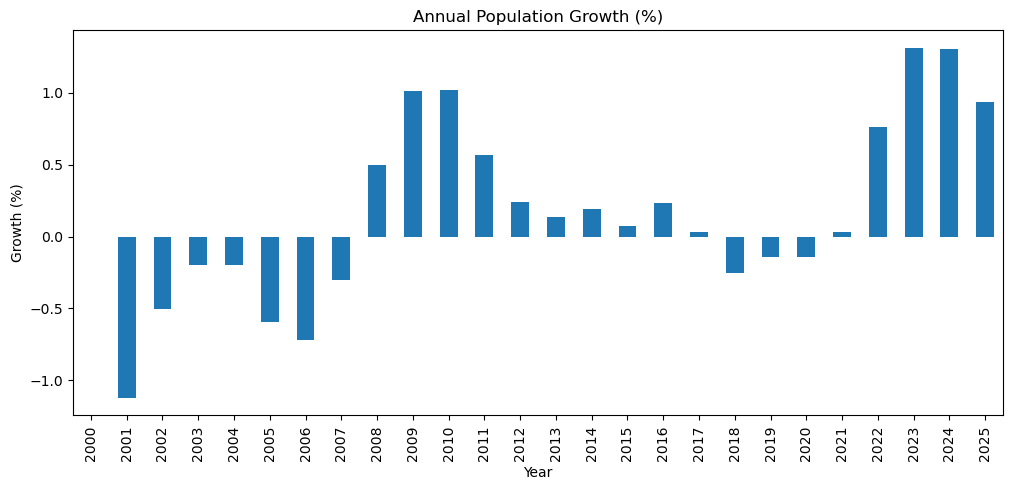

In [19]:
population.plot(
    x="REF_DATE",
    y="Growth_pct",
    kind="bar",
    title="Annual Population Growth (%)",
    xlabel="Year",
    ylabel="Growth (%)",
    legend=False,
    figsize=(12, 5)
)

### Висновок: щорічні темпи зміни населення

Аналіз відсоткової зміни чисельності населення Ньюфаундленду і Лабрадору за 2000–2025 роки показав нерівномірну демографічну динаміку.

У 2001–2007 роках спостерігалося щорічне скорочення населення. Починаючи з 2008 року ситуація покращилася, хоча в окремі роки знову фіксувалося зниження.

Найвищий річний темп приросту за досліджуваний період зафіксовано у **2023 році — приблизно 1,31%**.

Після 2021 року темпи зростання помітно прискорилися. Для пояснення цієї тенденції необхідно дослідити вплив природного приросту населення та міграційних процесів.

## 4. Аналіз компонентів демографічних змін

Досліджуємо вплив народжуваності, смертності та міграції на зміну чисельності населення Ньюфаундленду і Лабрадору.

Джерело: Statistics Canada, таблиця 17-10-0008-01.

In [20]:
migration_path = "../data/raw/17100008-eng/17100008.csv"

df_migration = pd.read_csv(migration_path)

df_migration.head()

,REF_DATE,GEO,DGUID,Components of population growth,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,1971/1972,Canada,2021A000011124,Births,Persons,249,units,0,v391069,1.10,351256.0,NaN,NaN,NaN,0
1,1971/1972,Canada,2021A000011124,Deaths,Persons,249,units,0,v391084,1.20,159533.0,NaN,NaN,NaN,0
2,1971/1972,Canada,2021A000011124,Immigrants,Persons,249,units,0,v391099,1.30,117036.0,NaN,NaN,NaN,0
3,1971/1972,Canada,2021A000011124,Net emigration,Persons,249,units,0,v1566834743,1.13,26577.0,NaN,NaN,NaN,0
4,1971/1972,Canada,2021A000011124,Emigrants,Persons,249,units,0,v29768526,1.90,66034.0,NaN,NaN,NaN,0


In [21]:
df_migration["Components of population growth"].unique()

array(['Births', 'Deaths', 'Immigrants', 'Net emigration', 'Emigrants',
       'Returning emigrants', 'Net non-permanent residents',
       'Residual deviation', 'Net interprovincial migration',
       'Net temporary emigration', 'Non-permanent residents, inflows',
       'Non-permanent residents, outflows'], dtype=object)

In [22]:
df_nl_migration = df_migration[
    df_migration["GEO"] == "Newfoundland and Labrador"
].copy()

df_nl_migration.head()

,REF_DATE,GEO,DGUID,Components of population growth,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
8,1971/1972,Newfoundland and Labrador,2021A000210,Births,Persons,249,units,0,v391070,2.10,12746.0,NaN,NaN,NaN,0
9,1971/1972,Newfoundland and Labrador,2021A000210,Deaths,Persons,249,units,0,v391085,2.20,3269.0,NaN,NaN,NaN,0
10,1971/1972,Newfoundland and Labrador,2021A000210,Immigrants,Persons,249,units,0,v391100,2.30,729.0,NaN,NaN,NaN,0
11,1971/1972,Newfoundland and Labrador,2021A000210,Net emigration,Persons,249,units,0,v1566834744,2.13,175.0,NaN,NaN,NaN,0
12,1971/1972,Newfoundland and Labrador,2021A000210,Emigrants,Persons,249,units,0,v29768530,2.90,441.0,NaN,NaN,NaN,0


In [23]:
# Виділяємо початковий рік із демографічного періоду
# Залишаємо дані за періоди з 2000/2001 до 2024/2025
df_nl_migration["Year"] = df_nl_migration["REF_DATE"].str[:4].astype(int)

df_nl_migration_clean = df_nl_migration[
    df_nl_migration["Year"].between(2000, 2024)
].copy()

df_nl_migration_clean["REF_DATE"].unique()

array(['2000/2001', '2001/2002', '2002/2003', '2003/2004', '2004/2005',
       '2005/2006', '2006/2007', '2007/2008', '2008/2009', '2009/2010',
       '2010/2011', '2011/2012', '2012/2013', '2013/2014', '2014/2015',
       '2015/2016', '2016/2017', '2017/2018', '2018/2019', '2019/2020',
       '2020/2021', '2021/2022', '2022/2023', '2023/2024', '2024/2025'],
      dtype=object)

In [24]:
# Підраховуємо кількість пропущених значень у стовпці VALUE
df_nl_migration_clean["VALUE"].isna().sum()

np.int64(48)

In [25]:
# Перевіряємо, у яких демографічних періодах
# та компонентах спостерігаються пропущені значення
df_nl_migration_clean[
    df_nl_migration_clean["VALUE"].isna()
][["REF_DATE", "Components of population growth", "VALUE"]]

,REF_DATE,Components of population growth,VALUE
3593,2000/2001,"Non-permanent residents, inflows",NaN
3594,2000/2001,"Non-permanent residents, outflows",NaN
3761,2001/2002,"Non-permanent residents, inflows",NaN
3762,2001/2002,"Non-permanent residents, outflows",NaN
3929,2002/2003,"Non-permanent residents, inflows",NaN
3930,2002/2003,"Non-permanent residents, outflows",NaN
4097,2003/2004,"Non-permanent residents, inflows",NaN
4098,2003/2004,"Non-permanent residents, outflows",NaN
4265,2004/2005,"Non-permanent residents, inflows",NaN
4266,2004/2005,"Non-permanent residents, outflows",NaN


In [26]:
# Групуємо дані за демографічними показниками
# Підраховуємо кількість пропущених значень для кожного показника
df_nl_migration_clean.groupby(
    "Components of population growth"
)["VALUE"].apply(lambda x: x.isna().sum())

Components of population growth
Births                                0
Deaths                                0
Emigrants                             0
Immigrants                            0
Net emigration                        0
Net interprovincial migration         0
Net non-permanent residents           0
Net temporary emigration              6
Non-permanent residents, inflows     21
Non-permanent residents, outflows    21
Residual deviation                    0
Returning emigrants                   0
Name: VALUE, dtype: int64

### Перевірка пропущених значень і підготовка даних

У наборі даних виявлено 48 пропущених значень, які стосуються трьох міграційних показників:

- Net temporary emigration — 6 пропусків.
- Non-permanent residents, inflows — 21 пропуск.
- Non-permanent residents, outflows — 21 пропуск.

Пропущені значення залишено без змін, оскільки відсутність даних не означає нульового значення показника.

Для подальшого аналізу таблицю перетворено з довгого формату в широкий за допомогою `pivot()`. Це дозволяє порівнювати різні компоненти демографічних змін у межах одного періоду.

In [27]:
# Перетворюємо дані з довгого формату (long) у широкий (wide)
# Кожен демографічний період стає окремим рядком
# Кожен показник стає окремим стовпцем
migration_wide = df_nl_migration_clean.pivot(
    index="REF_DATE",
    columns="Components of population growth",
    values="VALUE"
)

migration_wide.head()

Components of population growth,Births,Deaths,Emigrants,Immigrants,Net emigration,Net interprovincial migration,Net non-permanent residents,Net temporary emigration,"Non-permanent residents, inflows","Non-permanent residents, outflows",Residual deviation,Returning emigrants
REF_DATE,,,,,,,,,,,,
2000/2001,4733.0,4234.0,286.0,445.0,297.0,-4493.0,-147.0,105.0,NaN,NaN,-1930.0,94.0
2001/2002,4640.0,4233.0,265.0,414.0,522.0,-3352.0,57.0,354.0,NaN,NaN,364.0,97.0
2002/2003,4598.0,4313.0,215.0,316.0,379.0,-1683.0,76.0,354.0,NaN,NaN,363.0,190.0
2003/2004,4602.0,4272.0,200.0,536.0,396.0,-2027.0,178.0,355.0,NaN,NaN,365.0,159.0
2004/2005,4546.0,4448.0,238.0,541.0,485.0,-3710.0,127.0,354.0,NaN,NaN,364.0,107.0


In [28]:
# Обчислюємо природну зміну населення
# Народжуваність мінус смертність
# Додатне значення означає природний приріст
# Від'ємне значення означає природне скорочення
migration_wide["Natural_change"] = (
    migration_wide["Births"] - migration_wide["Deaths"]
)

migration_wide[["Births", "Deaths", "Natural_change"]].head()

Components of population growth,Births,Deaths,Natural_change
REF_DATE,,,
2000/2001,4733.0,4234.0,499.0
2001/2002,4640.0,4233.0,407.0
2002/2003,4598.0,4313.0,285.0
2003/2004,4602.0,4272.0,330.0
2004/2005,4546.0,4448.0,98.0


In [29]:
# Знаходимо періоди, коли смертність перевищувала народжуваність
# Виводимо перші п'ять таких періодів
migration_wide[
    migration_wide["Natural_change"] < 0
][["Births", "Deaths", "Natural_change"]].head()

Components of population growth,Births,Deaths,Natural_change
REF_DATE,,,
2006/2007,4500.0,4693.0,-193.0
2011/2012,4373.0,4638.0,-265.0
2012/2013,4457.0,4761.0,-304.0
2013/2014,4601.0,4821.0,-220.0
2014/2015,4473.0,5263.0,-790.0


In [30]:
# Переглядаємо народжуваність, смертність і природну зміну
# за останні 10 демографічних періодів
migration_wide[["Births", "Deaths", "Natural_change"]].tail(10)

Components of population growth,Births,Deaths,Natural_change
REF_DATE,,,
2015/2016,4435.0,5018.0,-583.0
2016/2017,4391.0,5153.0,-762.0
2017/2018,3989.0,5139.0,-1150.0
2018/2019,3893.0,5208.0,-1315.0
2019/2020,3700.0,5381.0,-1681.0
2020/2021,3694.0,5451.0,-1757.0
2021/2022,3800.0,6290.0,-2490.0
2022/2023,3321.0,6299.0,-2978.0
2023/2024,3315.0,6301.0,-2986.0


<Axes: title={'center': 'Births vs Deaths in Newfoundland and Labrador'}, xlabel='Demographic period', ylabel='Number of people'>

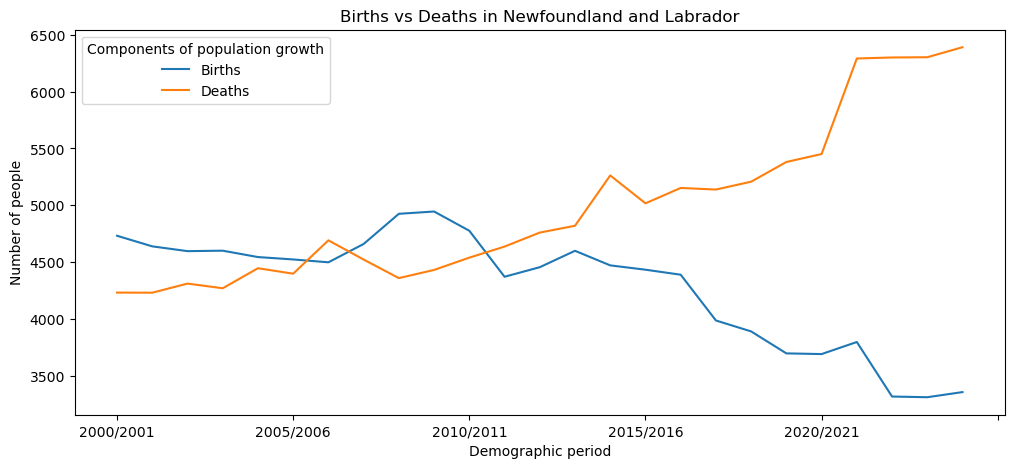

In [31]:
# Будуємо лінійний графік народжуваності та смертності
# Порівнюємо динаміку двох показників у часі
migration_wide[["Births", "Deaths"]].plot(
    kind="line",
    title="Births vs Deaths in Newfoundland and Labrador",
    xlabel="Demographic period",
    ylabel="Number of people",
    figsize=(12, 5)
)

In [32]:
# Обчислюємо зміну кількості смертей порівняно з попереднім періодом
migration_wide["Deaths_change"] = migration_wide["Deaths"].diff()

migration_wide[["Deaths", "Deaths_change"]].tail(10)

Components of population growth,Deaths,Deaths_change
REF_DATE,,
2015/2016,5018.0,-245.0
2016/2017,5153.0,135.0
2017/2018,5139.0,-14.0
2018/2019,5208.0,69.0
2019/2020,5381.0,173.0
2020/2021,5451.0,70.0
2021/2022,6290.0,839.0
2022/2023,6299.0,9.0
2023/2024,6301.0,2.0


In [33]:
# Обчислюємо зміну кількості народжень порівняно з попереднім періодом
# Порівнюємо щорічні зміни народжуваності та смертності
# Переглядаємо результати за останні 10 періодів
migration_wide["Births_change"] = migration_wide["Births"].diff()

migration_wide[
    ["Births", "Births_change", "Deaths", "Deaths_change"]
].tail(10)

Components of population growth,Births,Births_change,Deaths,Deaths_change
REF_DATE,,,,
2015/2016,4435.0,-38.0,5018.0,-245.0
2016/2017,4391.0,-44.0,5153.0,135.0
2017/2018,3989.0,-402.0,5139.0,-14.0
2018/2019,3893.0,-96.0,5208.0,69.0
2019/2020,3700.0,-193.0,5381.0,173.0
2020/2021,3694.0,-6.0,5451.0,70.0
2021/2022,3800.0,106.0,6290.0,839.0
2022/2023,3321.0,-479.0,6299.0,9.0
2023/2024,3315.0,-6.0,6301.0,2.0


### Висновок: природна зміна населення, народжуваність і смертність

Аналіз демографічних періодів 2000/2001–2024/2025 показав поступове погіршення природного балансу населення Ньюфаундленду і Лабрадору.

- У 2006/2007 році вперше за досліджуваний період зафіксовано природне скорочення населення (−193 особи).
- Починаючи з 2011/2012 року кількість смертей щороку перевищувала кількість народжень.
- Загалом народжуваність знижувалася, тоді як смертність зростала.
- У 2021/2022 році кількість смертей збільшилася на 839 осіб порівняно з попереднім періодом.
- У 2022/2023 році кількість народжень скоротилася на 479 осіб.
- У 2024/2025 році народжуваність дещо зросла (+45), проте смертність також збільшилася (+88). Загалом народилося 3 360 осіб, померло 6 389 осіб, а природне скорочення становило 3 029 осіб.

**Аналітичний висновок:** природне скорочення населення стало стійкою демографічною тенденцією, пов'язаною зі зниженням народжуваності та зростанням смертності. За таких умов міграція набуває особливого значення для підтримання чисельності населення провінції.

Різке збільшення смертності у 2021/2022 році потребує додаткового дослідження. Наявні дані не дозволяють визначити, якою мірою воно пов'язане з пандемією COVID-19 або старінням населення.

### Аналіз чисельності жінок віком 20–39 років

Для глибшого розуміння демографічних тенденцій окремо дослідимо зміну чисельності жінок віком 20–39 років у Ньюфаундленді й Лабрадорі за 2000–2025 роки.

Ця вікова група охоплює значну частину репродуктивного віку, тому її динаміка допомагає оцінити один із демографічних чинників, пов'язаних із народжуваністю.

Водночас зміна чисельності цієї групи сама по собі не пояснює всіх причин зниження народжуваності.

In [34]:
# Визначаємо вікові групи без перетинів
age_groups = [
    "20 to 24 years",
    "25 to 29 years",
    "30 to 34 years",
    "35 to 39 years"
]

# Відбираємо жінок віком 20–39 років у Newfoundland and Labrador
# за період 2000–2025 років
women_20_39 = df[
    (df["GEO"] == "Newfoundland and Labrador") &
    (df["Gender"] == "Women+") &
    (df["Age group"].isin(age_groups)) &
    (df["REF_DATE"].between(2000, 2025))
].copy()

women_20_39.head()

,REF_DATE,GEO,DGUID,Gender,Age group,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
151542,2000,Newfoundland and Labrador,2021A000210,Women+,20 to 24 years,Persons,249,units,0,v467075,2.3.31,18005.0,NaN,NaN,NaN,0
151548,2000,Newfoundland and Labrador,2021A000210,Women+,25 to 29 years,Persons,249,units,0,v467093,2.3.37,17326.0,NaN,NaN,NaN,0
151554,2000,Newfoundland and Labrador,2021A000210,Women+,30 to 34 years,Persons,249,units,0,v467114,2.3.43,19905.0,NaN,NaN,NaN,0
151560,2000,Newfoundland and Labrador,2021A000210,Women+,35 to 39 years,Persons,249,units,0,v467132,2.3.49,22408.0,NaN,NaN,NaN,0
157380,2001,Newfoundland and Labrador,2021A000210,Women+,20 to 24 years,Persons,249,units,0,v467075,2.3.31,17781.0,NaN,NaN,NaN,0


In [35]:
# Залишаємо лише стовпці, необхідні для аналізу вікових груп 
women_20_39 = women_20_39[
    ["REF_DATE", "Age group", "VALUE"]
].copy()

women_20_39.head()

,REF_DATE,Age group,VALUE
151542,2000,20 to 24 years,18005.0
151548,2000,25 to 29 years,17326.0
151554,2000,30 to 34 years,19905.0
151560,2000,35 to 39 years,22408.0
157380,2001,20 to 24 years,17781.0


In [36]:
# Підсумовуємо кількість жінок віком 20–39 років за кожен рік
women_by_year = women_20_39.groupby("REF_DATE")["VALUE"].sum()

women_by_year

REF_DATE
2000    77644.0
2001    75314.0
2002    73661.0
2003    72264.0
2004    70833.0
2005    68652.0
2006    66703.0
2007    65259.0
2008    64802.0
2009    64952.0
2010    65362.0
2011    65171.0
2012    64492.0
2013    63655.0
2014    62615.0
2015    61703.0
2016    61130.0
2017    60172.0
2018    58970.0
2019    58187.0
2020    57351.0
2021    56869.0
2022    57183.0
2023    58735.0
2024    60458.0
2025    61762.0
Name: VALUE, dtype: float64

In [37]:
# Розраховуємо зміну чисельності жінок віком 20–39 років
change_pct = (
    (women_by_year.loc[2025] - women_by_year.loc[2000])
    / women_by_year.loc[2000]
) * 100

print(f"Зміна чисельності: {change_pct:.2f}%")

Зміна чисельності: -20.45%


<Axes: title={'center': 'Women Aged 20–39 in Newfoundland and Labrador'}, xlabel='Year', ylabel='Number of women'>

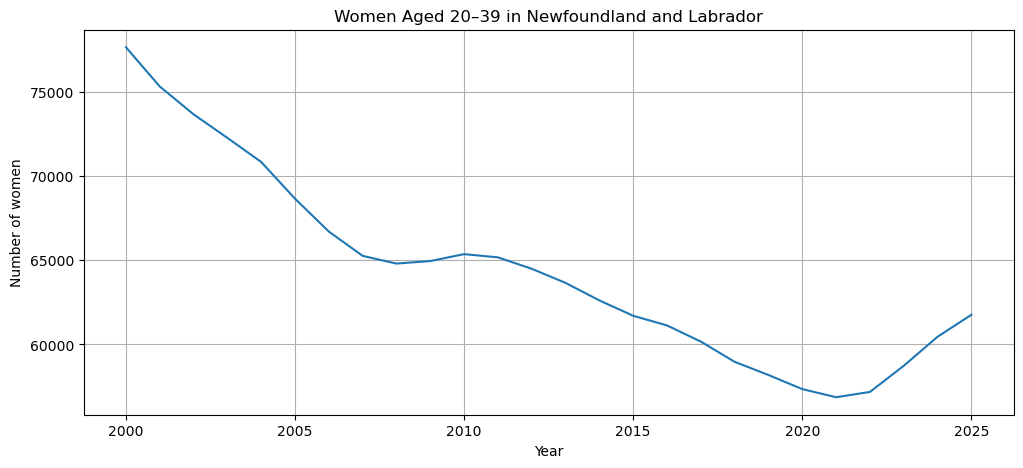

In [38]:
# Візуалізуємо зміну чисельності жінок віком 20–39 років
women_by_year.plot(
    kind="line",
    title="Women Aged 20–39 in Newfoundland and Labrador",
    xlabel="Year",
    ylabel="Number of women",
    figsize=(12, 5),
    grid=True
)

### Висновок: динаміка чисельності жінок віком 20–39 років

Аналіз даних Statistics Canada за 2000–2025 роки показав:

- У 2000 році чисельність жінок віком 20–39 років становила **77 644 особи**.
- До 2021 року цей показник скоротився до **56 869 осіб**.
- Починаючи з 2022 року спостерігається поступове відновлення чисельності цієї вікової групи.
- У 2025 році чисельність становила **61 762 особи**, що на **20,45% менше**, ніж у 2000 році.

**Аналітичний висновок:** тривале скорочення чисельності жінок віком 20–39 років могло бути одним із чинників зниження кількості народжень у провінції. Водночас після 2021 року чисельність цієї групи почала зростати, хоча загальна кількість народжень залишалася низькою.

Це свідчить про необхідність враховувати не лише чисельність жінок, а й вікові коефіцієнти народжуваності. Самих цих даних недостатньо для встановлення причинно-наслідкового зв'язку.

### Аналіз міграційних процесів у Ньюфаундленді й Лабрадорі

Оскільки природна зміна населення протягом останніх років залишається від'ємною, важливо дослідити роль міграції у зміні чисельності населення провінції.

У цьому розділі розглянемо три основні показники:

- **Міжпровінційна міграція** — різниця між кількістю людей, які переїхали до провінції з інших регіонів Канади, та кількістю тих, хто виїхав.
- **Імміграція** — кількість людей, які прибули до провінції як іммігранти.
- **Зміна чисельності тимчасових резидентів** — чиста зміна кількості осіб із тимчасовим статусом, які враховуються в оцінках населення.

Мета аналізу — визначити, як ці компоненти змінювалися протягом 2000/2001–2024/2025 років і яку роль вони відігравали в демографічній динаміці провінції.

In [39]:
# Переглядаємо міжнародну та міжпровінційну міграціюза останні п'ять демографічних періодів
migration_wide[
    [
        "Immigrants",
        "Net non-permanent residents",
        "Net interprovincial migration"
    ]
].tail(5)

Components of population growth,Immigrants,Net non-permanent residents,Net interprovincial migration
REF_DATE,,,
2020/2021,884.0,-459.0,527.0
2021/2022,2841.0,2027.0,1802.0
2022/2023,5337.0,3706.0,1060.0
2023/2024,5333.0,3778.0,1091.0
2024/2025,5470.0,983.0,1881.0


<Axes: title={'center': 'Net Interprovincial Migration in Newfoundland and Labrador'}, xlabel='Year', ylabel='Net migration (people)'>

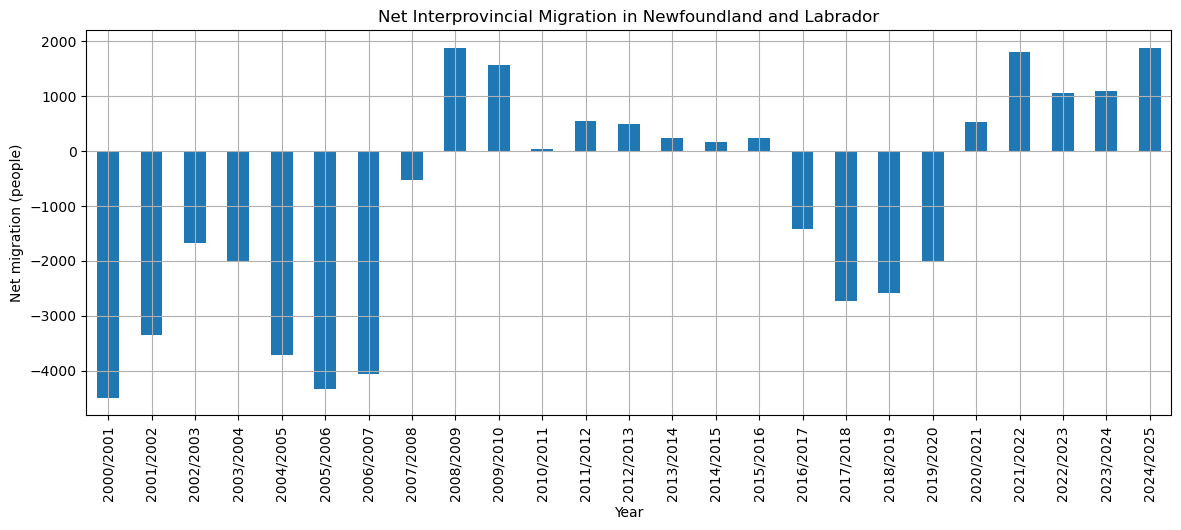

In [40]:
# Візуалізуємо сальдо міжпровінційної міграції за 2000–2025 роки
migration_wide["Net interprovincial migration"].plot(
    kind="bar",
    title="Net Interprovincial Migration in Newfoundland and Labrador",
    xlabel="Year",
    ylabel="Net migration (people)",
    figsize=(14, 5),
    grid=True
)

<Axes: title={'center': 'Immigration to Newfoundland and Labrador'}, xlabel='Year', ylabel='Number of immigrants'>

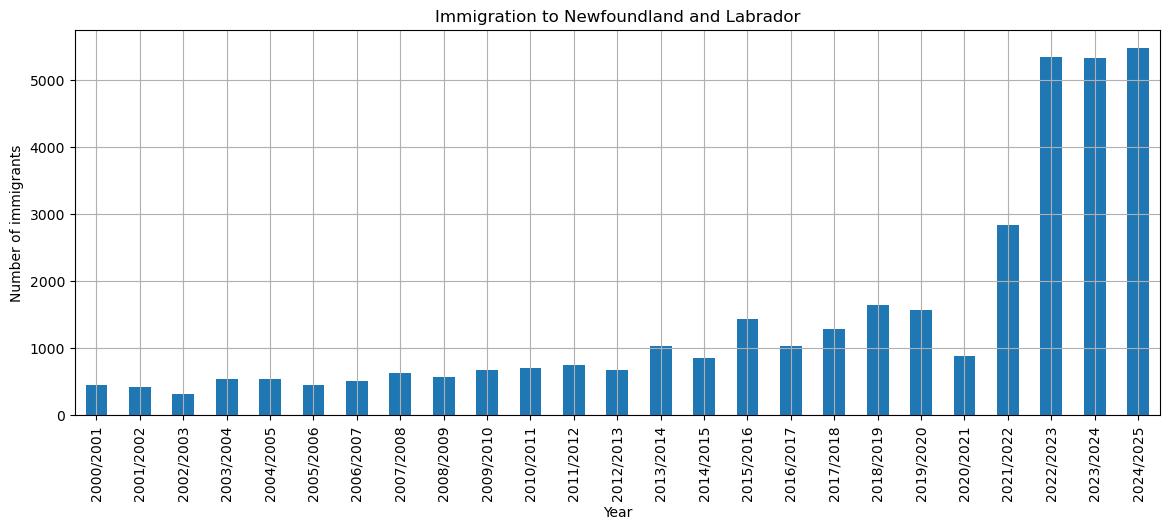

In [41]:
# Візуалізуємо кількість іммігрантів за весь досліджуваний період
migration_wide["Immigrants"].plot(
    kind="bar",
    title="Immigration to Newfoundland and Labrador",
    xlabel="Year",
    ylabel="Number of immigrants",
    figsize=(14, 5),
    grid=True
)

<Axes: title={'center': 'Net Change in Non-Permanent Residents in Newfoundland and Labrador'}, xlabel='Year', ylabel='Net change (people)'>

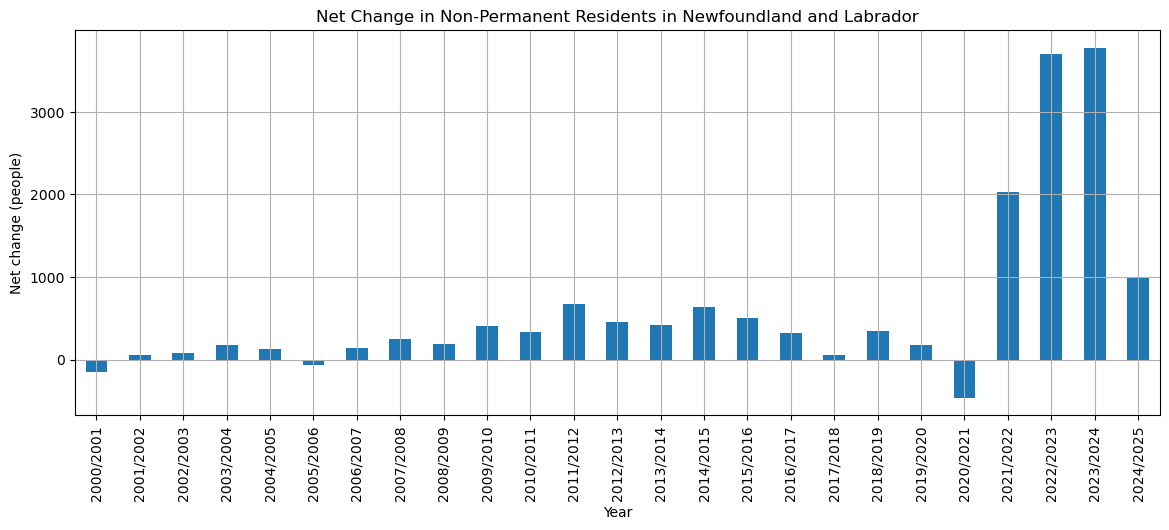

In [42]:
# Візуалізуємо зміну чисельності тимчасових резидентів
migration_wide["Net non-permanent residents"].plot(
    kind="bar",
    title="Net Change in Non-Permanent Residents in Newfoundland and Labrador",
    xlabel="Year",
    ylabel="Net change (people)",
    figsize=(14, 5),
    grid=True
)

### Детальний аналіз тимчасових резидентів (2021/2022–2024/2025)

Після аналізу загальних міграційних тенденцій окремо розглянемо приплив і вибуття тимчасових резидентів упродовж останніх чотирьох демографічних періодів.

Детальні дані про приплив і вибуття доступні починаючи з 2021/2022 року.

Мета аналізу — визначити, як змінювалися міграційні потоки тимчасових резидентів і чому їхній чистий приріст уповільнився в останньому періоді.

In [43]:
# Порівнюємо потоки тимчасових резидентів за останні роки
migration_wide[
    [
        "Non-permanent residents, inflows",
        "Non-permanent residents, outflows",
        "Net non-permanent residents"
    ]
].tail(5)

Components of population growth,"Non-permanent residents, inflows","Non-permanent residents, outflows",Net non-permanent residents
REF_DATE,,,
2020/2021,NaN,NaN,-459.0
2021/2022,5100.0,3073.0,2027.0
2022/2023,7682.0,3976.0,3706.0
2023/2024,8221.0,4443.0,3778.0
2024/2025,6154.0,5171.0,983.0


### Аналіз міграції тимчасових резидентів

У демографічні періоди 2021/2022–2024/2025 Ньюфаундленд і Лабрадор демонстрував значне збільшення чисельності тимчасових резидентів. Найвищий чистий приріст зафіксовано у 2023/2024 році (+3 778 осіб).
У 2024/2025 році чистий приріст скоротився до +983 осіб. Це пояснюється одночасним зменшенням припливу на 25,1% та збільшенням вибуття з категорії тимчасових резидентів на 16,4%.
Отримані дані свідчать про суттєве уповільнення зростання чисельності тимчасових резидентів, але не про скорочення їхньої загальної кількості.
**Питання для подальшого дослідження:** чи пов'язана ця зміна з федеральною імміграційною політикою, переходом тимчасових резидентів на PR або змінами на ринку праці?

<Axes: title={'center': 'Migration Trends in Newfoundland and Labrador'}, xlabel='Year', ylabel='Number of people'>

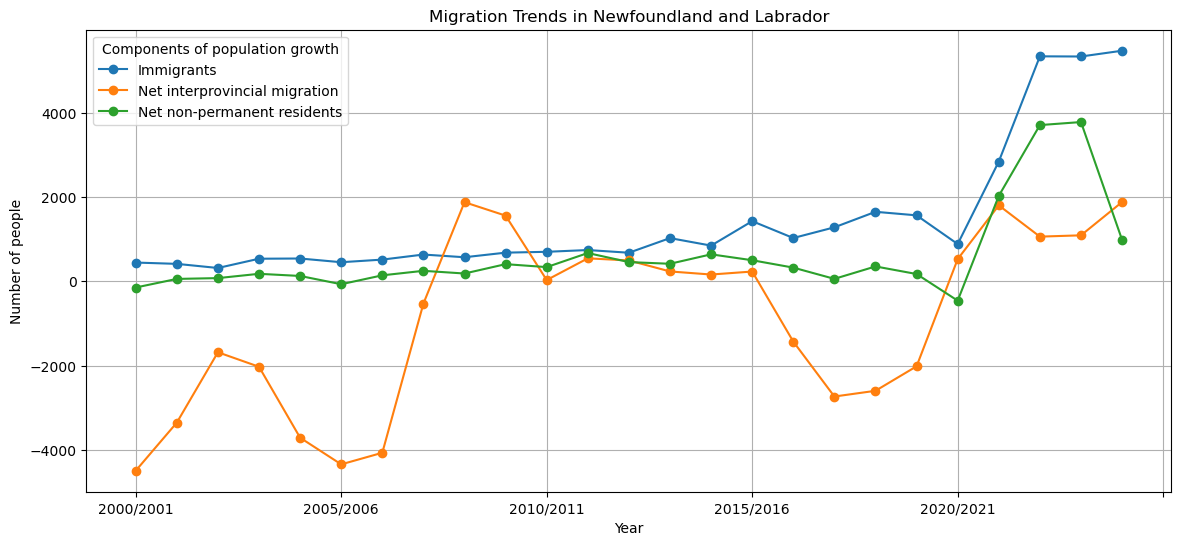

In [44]:
# Порівнюємо основні компоненти міграції за 2000–2025 роки
migration_wide[
    [
        "Immigrants",
        "Net interprovincial migration",
        "Net non-permanent residents"
    ]
].plot(
    kind="line",
    marker="o",
    figsize=(14, 6),
    title="Migration Trends in Newfoundland and Labrador",
    xlabel="Year",
    ylabel="Number of people",
    grid=True
)

### Висновки щодо міграції за 2000–2025 роки
Аналіз міграційних показників Ньюфаундленду і Лабрадору виявив три основні етапи:
- **2000–2007:** значне від'ємне сальдо міжпровінційної міграції, яке сприяло скороченню населення.
- **2008–2020:** коливання міжпровінційної міграції між додатними та від'ємними значеннями на тлі поступового зростання міжнародної імміграції.
- **2021–2025:** різке збільшення міжнародної імміграції, додатне сальдо міжпровінційної міграції та значний приріст тимчасових резидентів.
У 2024/2025 році міжнародна імміграція досягла 5 470 осіб, тоді як чистий приріст тимчасових резидентів сповільнився до 983 осіб.
**Загальний висновок:** міграція відігравала важливу роль у демографічних змінах провінції. Якщо на початку досліджуваного періоду переважав міжпровінційний відтік, то останніми роками міграційні потоки стали важливим джерелом поповнення населення.

In [45]:
# Порівнюємо природну зміну населення з основними міграційними показниками
migration_wide[
    [
        "Natural_change",
        "Immigrants",
        "Net interprovincial migration",
        "Net non-permanent residents"
    ]
].tail(10)

Components of population growth,Natural_change,Immigrants,Net interprovincial migration,Net non-permanent residents
REF_DATE,,,,
2015/2016,-583.0,1427.0,232.0,500.0
2016/2017,-762.0,1027.0,-1430.0,325.0
2017/2018,-1150.0,1281.0,-2733.0,58.0
2018/2019,-1315.0,1649.0,-2597.0,353.0
2019/2020,-1681.0,1565.0,-2016.0,173.0
2020/2021,-1757.0,884.0,527.0,-459.0
2021/2022,-2490.0,2841.0,1802.0,2027.0
2022/2023,-2978.0,5337.0,1060.0,3706.0
2023/2024,-2986.0,5333.0,1091.0,3778.0


### Висновок: роль міграції на тлі природного скорочення населення
У 2024/2025 році:
- Народилося на 3 029 людей менше, ніж померло.
- Було враховано 5 470 іммігрантів.
- Міжпровінційна міграція дала +1 881.
- Чисельність тимчасових резидентів збільшилася на 983.
Тобто міграційні компоненти не лише компенсували природне скорочення, а й створили умови для загального зростання населення. Для точного розрахунку загальної зміни ще потрібно врахувати еміграцію та інші компоненти.

In [46]:
# Порівнюємо природну зміну та міграційні показники за весь період
migration_wide[
    [
        "Natural_change",
        "Immigrants",
        "Net interprovincial migration",
        "Net non-permanent residents"
    ]
].describe().round(1)

Components of population growth,Natural_change,Immigrants,Net interprovincial migration,Net non-permanent residents
count,25.0,25.0,25.0,25.0
mean,-692.3,1436.5,-859.4,606.8
std,1176.5,1581.0,2098.3,1047.3
min,-3029.0,316.0,-4493.0,-459.0
25%,-1315.0,541.0,-2597.0,127.0
50%,-265.0,742.0,30.0,325.0
75%,236.0,1427.0,545.0,500.0
max,565.0,5470.0,1881.0,3778.0


### Статистичний підсумок демографічних змін за 2000–2025 роки
За 25 демографічних періодів середня природна зміна населення становила −692 особи, а середнє сальдо міжпровінційної міграції — −859 осіб.
Водночас середня кількість іммігрантів становила 1 437 осіб за період, а середня чиста зміна чисельності тимчасових резидентів — +607 осіб.
Отже, протягом досліджуваного періоду природне скорочення та міжпровінційний відтік населення протидіяли його зростанню, тоді як міжнародна імміграція та збільшення чисельності тимчасових резидентів частково компенсували ці втрати.
Останні роки характеризуються значно вищими показниками міжнародної імміграції порівняно з історичним середнім.

### Перевірка демографічного балансу

Після аналізу природної зміни населення та міграційних процесів перевіримо, наскільки розраховані демографічні компоненти узгоджуються зі зміною чисельності населення провінції.

Для цього об'єднаємо показники природної зміни, міжнародної та міжпровінційної міграції, а також статистичну поправку там, де вона доступна.

Мета перевірки — оцінити узгодженість розрахунків з офіційними даними Statistics Canada.

In [47]:
# Розраховуємо зміну населення за всі 25 демографічних періодів
migration_wide["Calculated_change"] = (
    migration_wide["Natural_change"]
    + migration_wide["Immigrants"]
    - migration_wide["Net emigration"]
    + migration_wide["Net non-permanent residents"]
    + migration_wide["Net interprovincial migration"]
    + migration_wide["Residual deviation"]
)

# Переглядаємо результати за всі періоди
migration_wide[["Natural_change", "Calculated_change"]]

Components of population growth,Natural_change,Calculated_change
REF_DATE,,
2000/2001,499.0,-5923.0
2001/2002,407.0,-2632.0
2002/2003,285.0,-1022.0
2003/2004,330.0,-1014.0
2004/2005,98.0,-3065.0
2005/2006,125.0,-3717.0
2006/2007,-193.0,-1546.0
2007/2008,137.0,2522.0
2008/2009,565.0,5172.0


In [48]:
# Створюємо копію таблиці з розрахованою зміною населення
comparison = migration_wide[["Calculated_change"]].copy()

# Отримуємо кінцевий рік демографічного періоду
comparison["Year"] = comparison.index.str[-4:].astype(int)

# Додаємо офіційну річну зміну населення
comparison = comparison.merge(
    population[["REF_DATE", "Change"]],
    left_on="Year",
    right_on="REF_DATE",
    how="left"
)

# Обчислюємо різницю між нашим розрахунком та офіційними даними
comparison["Difference"] = (
    comparison["Calculated_change"] - comparison["Change"]
)

# Переглядаємо результат
comparison[["Year", "Calculated_change", "Change", "Difference"]]

,Year,Calculated_change,Change,Difference
0,2001,-5923.0,-5923.0,0.0
1,2002,-2632.0,-2632.0,0.0
2,2003,-1022.0,-1022.0,0.0
3,2004,-1014.0,-1014.0,0.0
4,2005,-3065.0,-3065.0,0.0
5,2006,-3717.0,-3717.0,0.0
6,2007,-1546.0,-1546.0,0.0
7,2008,2522.0,2522.0,0.0
8,2009,5172.0,5172.0,0.0
9,2010,5261.0,5261.0,0.0


In [49]:
# Розраховуємо зміну населення без статистичної поправки
migration_wide["Change_without_residual"] = (
    migration_wide["Natural_change"]
    + migration_wide["Immigrants"]
    - migration_wide["Net emigration"]
    + migration_wide["Net non-permanent residents"]
    + migration_wide["Net interprovincial migration"]
)

# Переглядаємо останні п'ять періодів
migration_wide[
    ["Change_without_residual", "Residual deviation"]
].tail(5)

Components of population growth,Change_without_residual,Residual deviation
REF_DATE,,
2020/2021,-952.0,1124.0
2021/2022,4005.0,NaN
2022/2023,6980.0,NaN
2023/2024,7039.0,NaN
2024/2025,5122.0,NaN


In [50]:
# Об'єднуємо розрахунки за всі 25 демографічних періодів
migration_wide["Final_population_change"] = (
    migration_wide["Calculated_change"]
    .fillna(migration_wide["Change_without_residual"])
)

# Перевіряємо, чи залишилися пропущені значення
migration_wide["Final_population_change"].isna().sum()

np.int64(0)

### Перевірка демографічного балансу за 2000–2025 роки

Для перевірки результатів було розраховано зміну чисельності населення на основі природної зміни, міжнародної та міжпровінційної міграції, а також зміни чисельності тимчасових резидентів.

За 2000/2001–2020/2021 роки розрахунки зі статистичною поправкою (Residual deviation) збігаються з офіційними даними Statistics Canada.

За 2021/2022–2024/2025 роки статистична поправка відсутня, тому зміну населення розраховано без неї. Відсутність пропущених значень у результатах підтверджує повноту розрахункової таблиці, але не доводить збіг з офіційними показниками.

**Висновок:** демографічний баланс підтверджено для періодів із доступною статистичною поправкою. Результати за останні чотири періоди потребують окремої перевірки.

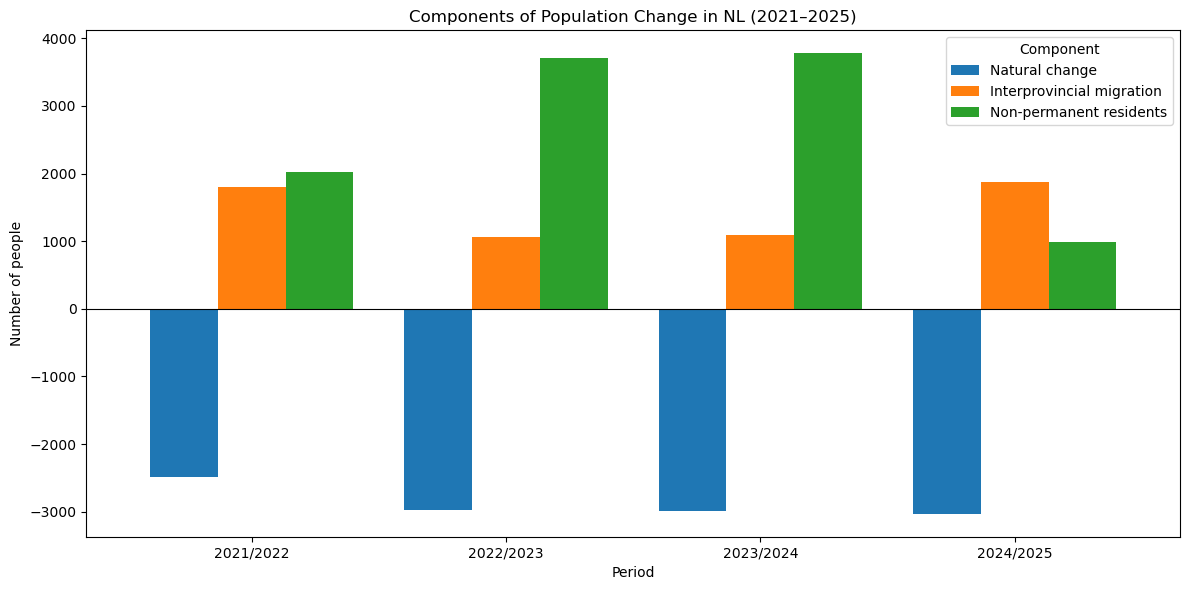

In [51]:

import pandas as pd
import matplotlib.pyplot as plt

# Останні чотири демографічні періоди
recent = migration_wide.loc[
    ["2021/2022", "2022/2023", "2023/2024", "2024/2025"]
].copy()

# Природна зміна населення
recent["Natural_change"] = recent["Births"] - recent["Deaths"]

# Окремі компоненти демографічних змін

components = pd.DataFrame({
    "Natural change": recent["Natural_change"],
    "Interprovincial migration": recent["Net interprovincial migration"],
    "Non-permanent residents": recent["Net non-permanent residents"]
})

# Будуємо графік
ax = components.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Components of Population Change in NL (2021–2025)")
ax.set_xlabel("Period")
ax.set_ylabel("Number of people")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Component")

plt.tight_layout()
plt.show()


### Висновок: компоненти зміни чисельності населення (2021/2022–2024/2025)
Аналіз демонструє три важливі демографічні тенденції в Ньюфаундленді і Лабрадорі:

* Природна зміна населення залишалася від’ємною протягом усіх чотирьох періодів, оскільки кількість смертей стабільно перевищувала кількість народжень.
* Чиста міжпровінційна міграція залишалася додатною, частково компенсуючи природне скорочення населення.
* Приріст кількості непостійних резидентів був особливо значним у 2022–2024 роках, але суттєво зменшився у 2024–2025 роках.

Висновок: Міграційні процеси відігравали важливу роль у компенсації природного скорочення населення Ньюфаундленду і Лабрадору. Водночас графік відображає не всі компоненти демографічних змін, тому його не можна розглядати як повний демографічний баланс.

## Українська міграція до Ньюфаундленду і Лабрадору після 2022 року

Після початку повномасштабного вторгнення Росії в Україну у 2022 році Ньюфаундленд і Лабрадор став одним із регіонів Канади, які приймали українців, змушених залишити свою країну через війну.

Для дослідження використано звіти Association for New Canadians (ANC), які містять інформацію про прибуття українців до провінції.

Мета цього розділу — проаналізувати помісячну динаміку прибуттів у 2023–2024 роках та розглянути додаткові показники української міграції.

In [52]:

# Помісячне прибуття українців до Newfoundland and Labrador

ukraine_arrivals = pd.DataFrame({
    "Month": pd.date_range("2023-04-01", periods=12, freq="MS"),
    "Arrivals": [70, 63, 92, 86, 84, 77, 95, 104, 107, 84, 217, 301]
})

display(ukraine_arrivals)


,Month,Arrivals
0,2023-04-01,70
1,2023-05-01,63
2,2023-06-01,92
3,2023-07-01,86
4,2023-08-01,84
5,2023-09-01,77
6,2023-10-01,95
7,2023-11-01,104
8,2023-12-01,107
9,2024-01-01,84


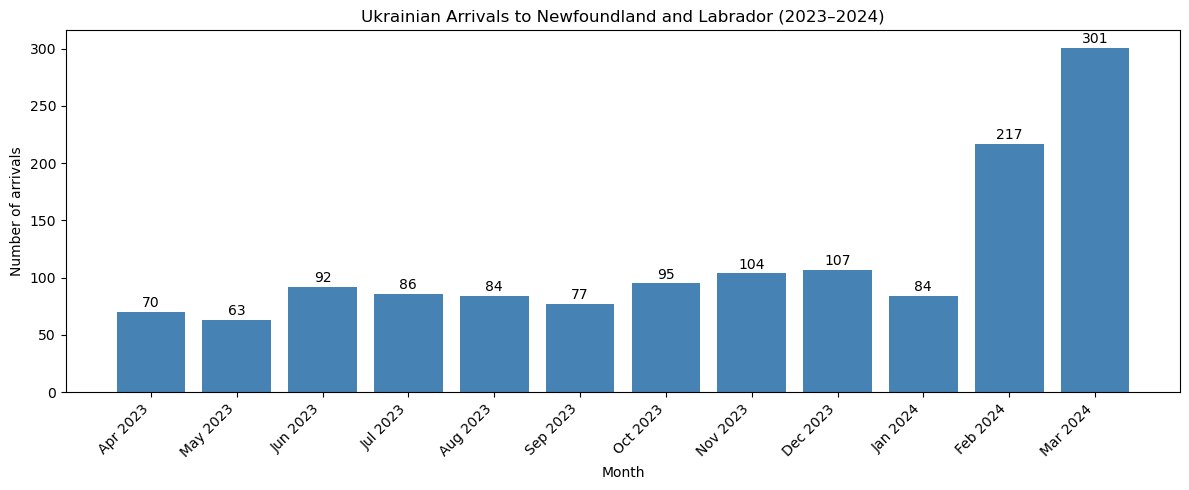

In [53]:

# Динаміка прибуття українців у 2023–2024 роках

plt.figure(figsize=(12, 5))

plt.bar(
    ukraine_arrivals["Month"].dt.strftime("%b %Y"),
    ukraine_arrivals["Arrivals"],
    color="steelblue"
)

plt.title("Ukrainian Arrivals to Newfoundland and Labrador (2023–2024)")
plt.xlabel("Month")
plt.ylabel("Number of arrivals")
plt.xticks(rotation=45, ha="right")

# Показуємо кількість людей над кожним стовпчиком
for i, value in enumerate(ukraine_arrivals["Arrivals"]):
    plt.text(i, value + 4, str(value), ha="center")

plt.tight_layout()
plt.show()


### Аналіз динаміки прибуття українців (2023–2024)

За даними Association for New Canadians, протягом квітня 2023 — березня 2024 року було зафіксовано **1 380 прибуттів українців** до Ньюфаундленду і Лабрадору.

Помісячний аналіз показує, що найбільша кількість прибуттів припала на лютий (217 осіб) та березень 2024 року (301 особа).

Разом за ці два місяці було зафіксовано **518 прибуттів, або 37,5%** від загальної кількості за досліджуваний період.

**Висновок:** Наприкінці фінансового року 2023–2024 спостерігалося помітне збільшення кількості прибуттів українців. Однак ці дані характеризують міграційний потік, а не чистий приріст населення, оскільки не враховують подальший відтік прибулих.

### Загальна кількість прибуттів та утримання українців у провінції

За даними Association for New Canadians (ANC), станом на 31 березня 2025 року до Ньюфаундленду і Лабрадору прибуло **4 410 українців**.

Згідно з інформацією, представленою під час парламентських слухань, рівень утримання українських новоприбулих у провінції становив:

- **86%** у квітні 2024 року.
- **82%** у травні 2025 року.

Різниця становить **4 відсоткові пункти**. Однак ці показники стосуються різних моментів часу та можуть охоплювати різні групи прибулих, тому їх не можна використовувати для точного розрахунку кількості українців, які виїхали з провінції.

**Підсумок:** Українська міграція була помітним міграційним процесом після 2022 року. Водночас наявні дані дозволяють оцінити кількість прибуттів і заявлені показники утримання, але не дають можливості точно визначити чистий внесок українців у зміну чисельності населення провінції.

## Загальні висновки дослідження (2000–2025)

Аналіз демографічних показників Ньюфаундленду і Лабрадору за 2000–2025 роки дозволив визначити кілька ключових тенденцій.

### 1. Динаміка чисельності населення

Протягом досліджуваного періоду чисельність населення провінції змінювалася нерівномірно. Після періодів скорочення та відносної стабільності в останні роки спостерігалося відновлення зростання.

### 2. Народжуваність і смертність

Однією з головних демографічних проблем є природне скорочення населення. В останні роки кількість смертей перевищувала кількість народжень.

Аналіз чисельності жінок віком 20–39 років дозволив додатково дослідити демографічний контекст народжуваності, але не встановлює безпосередніх причин її змін.

### 3. Вплив міграції

Міграційні процеси відігравали важливу роль у зміні чисельності населення провінції.

Особливо помітним після 2021 року став приріст кількості непостійних резидентів. Водночас додатна міжпровінційна міграція частково компенсувала природне скорочення населення.

### 4. Українська міграція

Окремий аналіз даних Association for New Canadians показав помітне збільшення прибуттів українців наприкінці фінансового року 2023–2024.

Українська міграція є одним із прикладів міграційних процесів після 2022 року, однак наявні дані не дозволяють точно визначити її чистий внесок у приріст населення провінції.

### 5. Підсумковий висновок

**Головний результат дослідження:** в останні роки зростання чисельності населення Ньюфаундленду і Лабрадору відбувалося на тлі природного скорочення, що підкреслює важливу роль міграційних процесів.

Для розуміння демографічної ситуації необхідно аналізувати не лише загальну чисельність населення, а й народжуваність, смертність, міжпровінційну та міжнародну міграцію і зміну кількості непостійних резидентів.

### Обмеження аналізу

Дослідження базується на агрегованих статистичних даних. Для окремих останніх періодів відсутні значення деяких компонентів міграції, тому повністю відтворити демографічний баланс за всі роки за допомогою наявних показників неможливо.

## Джерела даних (Data Sources)

### Statistics Canada

Основні статистичні дані про населення, народжуваність, смертність та міграцію Ньюфаундленду і Лабрадору за 2000–2025 роки:

- [Table 17-10-0005-01 — Population estimates on July 1, by age and gender](https://doi.org/10.25318/1710000501-eng)
- [Table 17-10-0008-01 — Estimates of the components of demographic growth, annual](https://doi.org/10.25318/1710000801-eng)
- [Table 17-10-0015-01 — Estimates of the components of interprovincial migration, by age and gender, annual](https://doi.org/10.25318/1710001501-eng)
- [Table 17-10-0022-01 — Estimates of interprovincial migrants by province or territory of origin and destination, annual](https://doi.org/10.25318/1710002201-eng)

### Association for New Canadians (ANC)

Джерела для аналізу української міграції:

- [ANC Annual Report 2023–2024](https://ancnl.ca/site/uploads/2025/03/Annual-Report-2023-2024_sm.pdf) — помісячна кількість прибуттів українців.
- [ANC Annual Report 2024–2025](https://ancnl.ca/site/uploads/2026/03/Annual-Report-2024-2025_sm.pdf.pdf) — загальна кількість прибулих українців станом на 31 березня 2025 року.

### Newfoundland and Labrador House of Assembly

Парламентські матеріали щодо утримання українських новоприбулих у провінції:

- [Resource Committee — April 17, 2024](https://www.assembly.nl.ca/Committees/StandingCommittees/Resource/ga50/24-04-17RCDeptofIPGS.htm) — показник утримання 86%.
- [Resource Committee — May 5, 2025](https://www.assembly.nl.ca/Committees/StandingCommittees/Resource/ga50/25-05-05RCDeptofIPGS.html) — показник утримання 82%.

### Примітка

Статистичні таблиці можуть оновлюватися та переглядатися Statistics Canada. Аналіз охоплює період до 2025 року. Дані ANC та Statistics Canada мають різні методології обліку, тому їхні показники не завжди можна порівнювати безпосередньо.